# Experiments 18,19,20
## Date: 25-11-2026

# 18.Choosing the Right Graph: Pie, Bar, Histogram and Box Plots 

Hospital Operations Dashboard: Choosing the Right Graph

Budget share (%)       : {'Cardiology': 28, 'Orthopaedics': 18, 'Neurology': 22, 'Paediatrics': 12, 'General': 20}
Patients 2025 vs 2026  :
  Cardiology      820   910  change = +11.0%
  Orthopaedics    640   700  change = +9.4%
  Neurology       410   455  change = +11.0%
  Paediatrics     930   880  change = -5.4%
  General        1500  1620  change = +8.0%

Patient age: n = 1289, mean = 42.9, median = 46.3, std = 23.2

Waiting time (minutes) summary by department:
              mean   25%   50%   75%   max
Cardiology    17.6  10.2  15.7  23.2  48.7
Orthopaedics  15.5   8.7  14.3  20.6  41.5
Neurology     25.1  17.2  23.5  30.9  59.2
Paediatrics   11.1   4.3   8.1  14.7  46.5
General       29.8  21.1  28.1  37.4  69.1


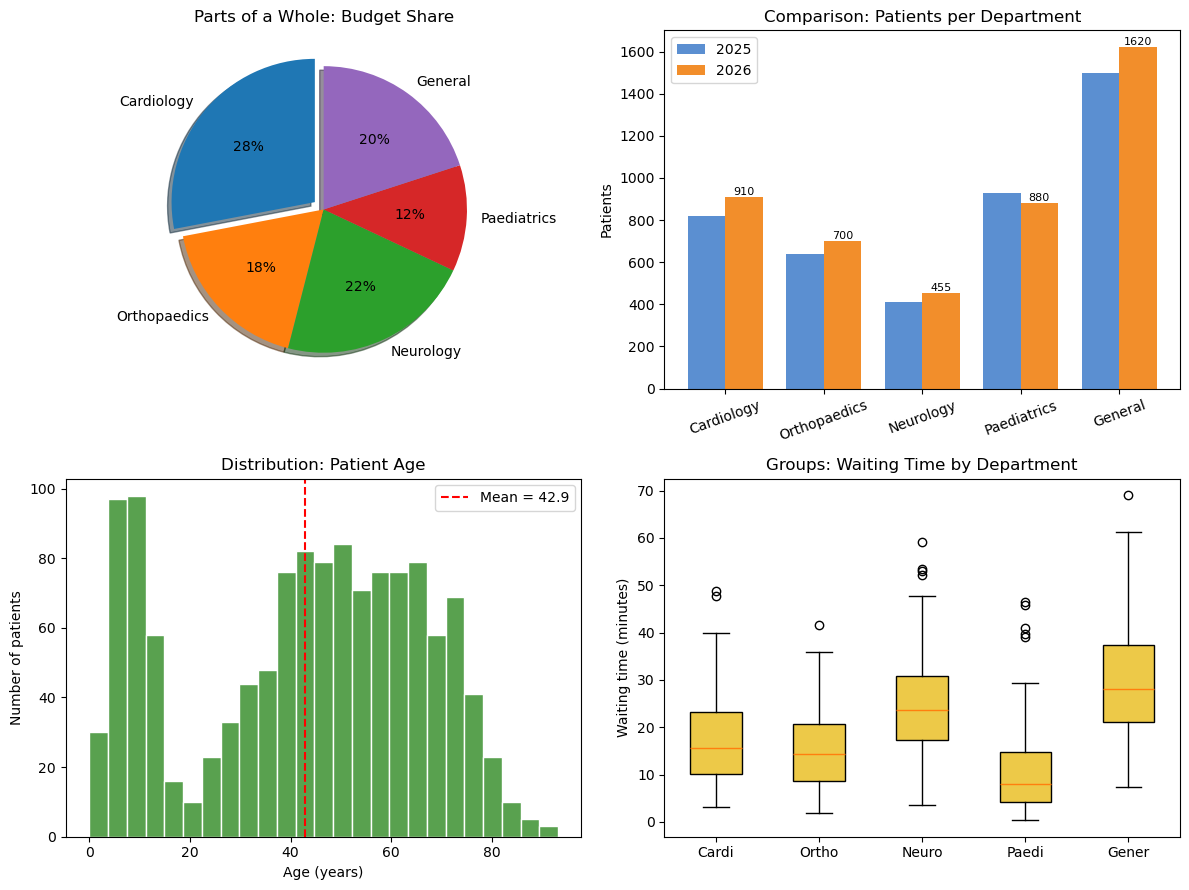


Saved figures: exp18_dashboard.png, exp18_barh.png


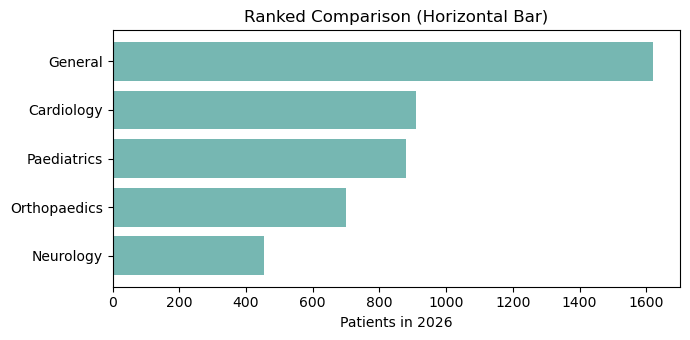

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
  
np.random.seed(11) 
departments = [ 
    "Cardiology", 
    "Orthopaedics", 
    "Neurology", 
    "Paediatrics", 
    "General", 
] 
budget_share = [28, 18, 22, 12, 20] 
patients_2025 = [820, 640, 410, 930, 1500] 
patients_2026 = [910, 700, 455, 880, 1620] 
wait = { 
    d: np.random.gamma(shape=k, scale=6, size=120) 
    for d, k in zip(departments, [3, 2.5, 4, 1.8, 5]) 
} 
ages = np.concatenate( 
    [ 
        np.random.normal(8, 4, 300), 
        np.random.normal(45, 12, 700), 
        np.random.normal(70, 8, 300), 
    ] 
) 
ages = ages[(ages > 0) & (ages < 100)] 
  
print("Hospital Operations Dashboard: Choosing the Right Graph") 
print("=" * 56) 
print("\nBudget share (%)       :", dict(zip(departments, budget_share))) 
print("Patients 2025 vs 2026  :") 
for d, a, b in zip(departments, patients_2025, patients_2026): 
    print(f"  {d:<13} {a:>5} {b:>5}  change = {100 * (b - a) / a:+.1f}%") 
print( 
    "\nPatient age: n = {}, mean = {:.1f}, median = {:.1f}, std = {:.1f}".format( 
        len(ages), ages.mean(), np.median(ages), ages.std() 
    ) 
) 
print("\nWaiting time (minutes) summary by department:") 
summary = ( 
    pd.DataFrame(wait).describe().T[["mean", "25%", "50%", "75%", "max"]].round(1) 
) 
print(summary.to_string()) 
  
fig, ax = plt.subplots(2, 2, figsize=(12, 9)) 
  
# Parts of a whole -> pie chart 
explode = [0.08 if s == max(budget_share) else 0 for s in budget_share] 
ax[0, 0].pie( 
    budget_share, 
    labels=departments, 
    autopct="%1.0f%%", 
    startangle=90, 
    explode=explode, 
    shadow=True, 
) 
ax[0, 0].set_title("Parts of a Whole: Budget Share") 
  
# Comparisons -> grouped bar chart 
x = np.arange(len(departments)) 
w = 0.38 
b1 = ax[0, 1].bar(x - w / 2, patients_2025, w, label="2025", color="#5b8fd1") 
b2 = ax[0, 1].bar(x + w / 2, patients_2026, w, label="2026", color="#f28e2b") 
ax[0, 1].bar_label(b2, fontsize=8) 
ax[0, 1].set_xticks(x, departments, rotation=20) 
ax[0, 1].set_ylabel("Patients") 
ax[0, 1].legend() 
ax[0, 1].set_title("Comparison: Patients per Department") 

# Distribution -> histogram 
ax[1, 0].hist(ages, bins=25, color="#59a14f", edgecolor="white") 
ax[1, 0].axvline( 
    ages.mean(), color="red", linestyle="--", label=f"Mean = {ages.mean():.1f}" 
) 
ax[1, 0].set_xlabel("Age (years)") 
ax[1, 0].set_ylabel("Number of patients") 
ax[1, 0].set_title("Distribution: Patient Age") 
ax[1, 0].legend() 
  
# Groups -> box plot 
ax[1, 1].boxplot( 
    wait.values(), 
    labels=[d[:5] for d in departments], 
    patch_artist=True, 
    boxprops=dict(facecolor="#edc948"), 
) 
ax[1, 1].set_ylabel("Waiting time (minutes)") 
ax[1, 1].set_title("Groups: Waiting Time by Department") 
  
plt.tight_layout() 
plt.savefig("exp18_dashboard.png", dpi=150) 
plt.show() 
  
# Horizontal bar ranked view 
fig, ax = plt.subplots(figsize=(7, 3.5)) 
order = np.argsort(patients_2026) 
ax.barh( 
    np.array(departments)[order], np.array(patients_2026)[order], color="#76b7b2" 
) 
ax.set_xlabel("Patients in 2026") 
ax.set_title("Ranked Comparison (Horizontal Bar)") 
plt.tight_layout() 
plt.savefig("exp18_barh.png", dpi=150) 
print("\nSaved figures: exp18_dashboard.png, exp18_barh.png") 

# 19.Scatterplots, Correlations and Geographic Data using Basemap

Basemap not found. Install with: pip install basemap (or use Cartopy)
Air Quality Analysis: Scatterplots, Correlation and Geographic Data
         city  vehicles_lakh  industries  green_cover  pm25
        Delhi            122          55           12  88.4
       Mumbai             45          70           10  68.7
      Kolkata             40          60            8  53.1
      Chennai             62          58           14  74.4
    Bengaluru            105          45           16  66.1
    Hyderabad             77          50           12  65.8
    Ahmedabad             45          75            9  74.9
         Pune             40          52           15  47.3
       Jaipur             30          30           11  36.8
      Lucknow             28          28           10  76.7
       Kanpur             17          48            7  92.3
        Patna             18          22            6  89.3
       Bhopal             16          25           21  25.2
        Kochi         

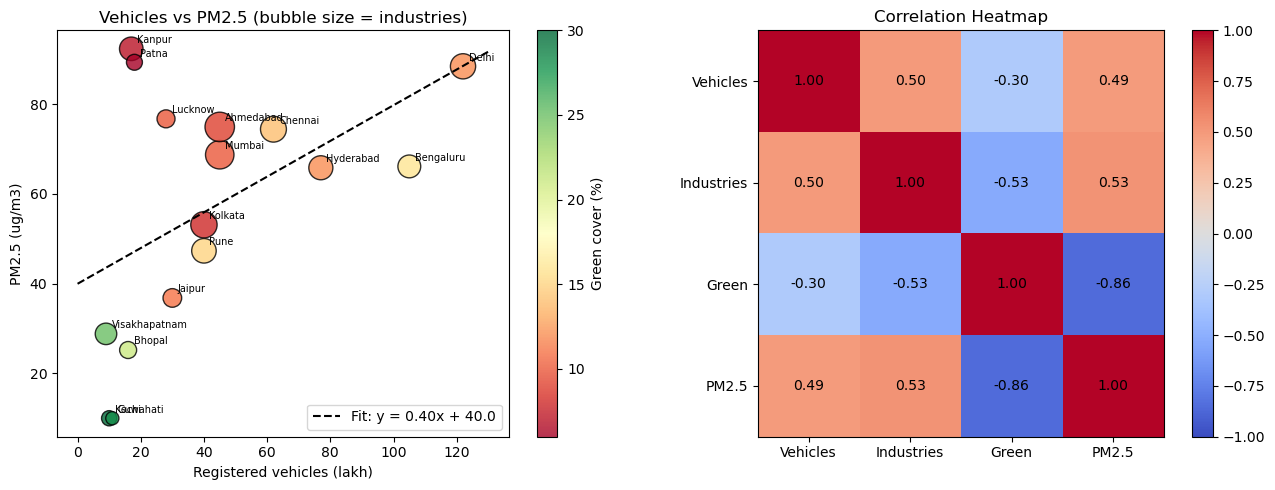

In [2]:
import warnings 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
  
# Basemap is a deprecated library: hide its deprecation warnings 
warnings.filterwarnings("ignore", category=DeprecationWarning) 
try: 
    from mpl_toolkits.basemap import Basemap 
except ImportError: 
    Basemap = None 
    print("Basemap not found. Install with: pip install basemap (or use Cartopy)") 
  
# city, latitude, longitude, vehicles (lakh), industries, green cover (%) 
records = [ 
    ("Delhi", 28.61, 77.21, 122, 55, 12), ("Mumbai", 19.08, 72.88, 45, 70, 10), 
    ("Kolkata", 22.57, 88.36, 40, 60, 8), ("Chennai", 13.08, 80.27, 62, 58, 14), 
    ("Bengaluru", 12.97, 77.59, 105, 45, 16), ("Hyderabad", 17.39, 78.49, 77, 50, 12), 
    ("Ahmedabad", 23.02, 72.57, 45, 75, 9), ("Pune", 18.52, 73.86, 40, 52, 15), 
    ("Jaipur", 26.91, 75.79, 30, 30, 11), ("Lucknow", 26.85, 80.95, 28, 28, 10), 
    ("Kanpur", 26.45, 80.33, 17, 48, 7), ("Patna", 25.59, 85.14, 18, 22, 6), 
    ("Bhopal", 23.26, 77.41, 16, 25, 21), ("Kochi", 9.93, 76.27, 10, 20, 30), 
    ("Visakhapatnam", 17.69, 83.22, 9, 40, 25), ("Guwahati", 26.14, 91.74, 11, 15, 28), 
] 
cols = ["city", "lat", "lon", "vehicles_lakh", "industries", "green_cover"] 
cities = pd.DataFrame(records, columns=cols) 
np.random.seed(2) 
cities["pm25"] = ( 
    25 + 0.4 * cities["vehicles_lakh"] + 0.5 * cities["industries"] 
    - 0.9 * cities["green_cover"] + np.random.normal(0, 5, len(cities)) 
).clip(lower=10).round(1) 
belt = cities["city"].isin(["Kanpur", "Patna", "Lucknow"])  # Indo-Gangetic belt 
cities.loc[belt, "pm25"] += 40 
  
print("Air Quality Analysis: Scatterplots, Correlation and Geographic Data") 
print("=" * 68) 
print( 
    cities[ 
        ["city", "vehicles_lakh", "industries", "green_cover", "pm25"] 
    ].to_string(index=False) 
) 
  
corr = cities[["vehicles_lakh", "industries", "green_cover", "pm25"]].corr() 
print("\nCorrelation matrix (Pearson):") 
print(corr.round(3).to_string()) 
for col in ["vehicles_lakh", "industries", "green_cover"]: 
    r = corr.loc[col, "pm25"] 
    strength = ( 
        "strong" if abs(r) > 0.6 else "moderate" if abs(r) > 0.3 else "weak" 
    ) 
    print( 
        f"  pm25 vs {col:<13}: r = {r:+.3f} " 
        f"({strength} {'positive' if r > 0 else 'negative'})" 
    ) 
print("\nMost polluted:", cities.nlargest(3, "pm25")["city"].tolist()) 
print("Least polluted:", cities.nsmallest(3, "pm25")["city"].tolist()) 
  
# ---------- Advanced scatter plot (colour + size + annotation + fit line) ---------- 
fig, ax = plt.subplots(1, 2, figsize=(13, 5)) 
sc = ax[0].scatter( 
    cities["vehicles_lakh"], 
    cities["pm25"], 
    s=cities["industries"] * 6, 
    c=cities["green_cover"], 
    cmap="RdYlGn", 
    edgecolors="black", 
    alpha=0.8, 
) 
m, b = np.polyfit(cities["vehicles_lakh"], cities["pm25"], 1) 
xs = np.linspace(0, 130, 50) 
ax[0].plot(xs, m * xs + b, "k--", label=f"Fit: y = {m:.2f}x + {b:.1f}") 
for _, r in cities.iterrows(): 
    ax[0].annotate( 
        r["city"], 
        (r["vehicles_lakh"], r["pm25"]), 
        fontsize=7, 
        xytext=(4, 4), 
        textcoords="offset points", 
    ) 
fig.colorbar(sc, ax=ax[0], label="Green cover (%)") 
ax[0].set_xlabel("Registered vehicles (lakh)") 
ax[0].set_ylabel("PM2.5 (ug/m3)") 
ax[0].set_title("Vehicles vs PM2.5 (bubble size = industries)") 
ax[0].legend() 
  
# ---------- Correlation heatmap ---------- 
im = ax[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1) 
labels = ["Vehicles", "Industries", "Green", "PM2.5"] 
ax[1].set_xticks(range(4), labels) 
ax[1].set_yticks(range(4), labels) 
for i in range(4): 
    for j in range(4): 
        ax[1].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center") 
fig.colorbar(im, ax=ax[1]) 
ax[1].set_title("Correlation Heatmap") 
plt.tight_layout() 
plt.savefig("exp19_scatter.png", dpi=150) 
  
# ---------- Geographic plot with Basemap ---------- 
if Basemap is not None: 
    plt.figure(figsize=(8, 8)) 
    mp = Basemap( 
        projection="merc", 
        llcrnrlat=6, 
        urcrnrlat=36, 
        llcrnrlon=67, 
        urcrnrlon=98, 
        resolution="l", 
    ) 
    mp.drawcoastlines(linewidth=0.6) 
    mp.drawcountries(linewidth=0.8) 
    mp.fillcontinents(color="#f2efe6", lake_color="#cfe8f7") 
    mp.drawmapboundary(fill_color="#cfe8f7") 
    mp.drawparallels(range(5, 40, 5), labels=[1, 0, 0, 0], fontsize=8) 
    mp.drawmeridians(range(65, 100, 5), labels=[0, 0, 0, 1], fontsize=8) 
    x, y = mp(cities["lon"].values, cities["lat"].values) 
    pts = mp.scatter( 
        x, 
        y, 
        s=cities["pm25"] * 4, 
        c=cities["pm25"], 
        cmap="YlOrRd", 
        edgecolors="black", 
        zorder=5, 
    ) 
    for xi, yi, name in zip(x, y, cities["city"]): 
        plt.text(xi + 30000, yi + 30000, name, fontsize=8, zorder=6) 
    plt.colorbar(pts, shrink=0.6, label="PM2.5 (ug/m3)") 
    plt.title("PM2.5 Levels across Indian Cities (Basemap)") 
    plt.savefig("exp19_map.png", dpi=150, bbox_inches="tight") 
    print("\nSaved figures: exp19_scatter.png, exp19_map.png") 
plt.show() 

# 20. Visualizing Undirected and Directed Graphs

Network Visualization: Undirected and Directed Graphs

Part A - Undirected collaboration network
Nodes: 9 | Edges: 12
Density: 0.333 | Connected: True
Researcher Degree  Betweenness
Fiona           4        0.589
Charu           4        0.429
Gautam          3        0.429
Deva            3        0.054
Asha            2        0.000
Bharath         2        0.000
Eswar           2        0.000
Hema            2        0.000
Irfan           2        0.000
Shortest path Asha -> Irfan: Asha - Charu - Fiona - Gautam - Irfan
Communities: [['Asha', 'Bharath', 'Charu'], ['Deva', 'Eswar', 'Fiona'], ['Gautam', 'Hema', 'Irfan']]

Part B - Directed flight network
Airports: 7 | Routes: 12
Airport     In  Out  PageRank
Delhi        3    2     0.202
Chennai      2    3     0.183
Kolkata      2    2     0.183
Bengaluru    2    2     0.146
Guwahati     1    0     0.113
Mumbai       1    2     0.087
Hyderabad    1    1     0.087
Shortest route Hyderabad -> Guwahati: Hyderabad -> Bengaluru -> Kolkata 

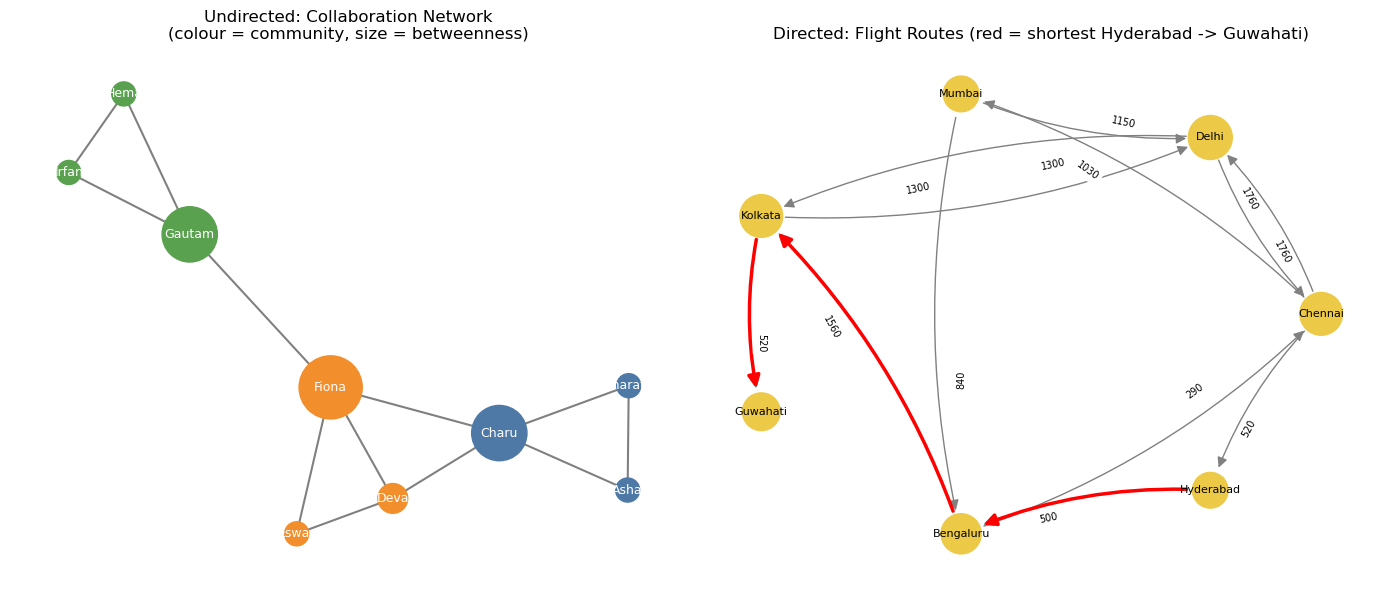


Saved figure: exp20_graphs.png


In [3]:
import networkx as nx 
import matplotlib.pyplot as plt 
  
print("Network Visualization: Undirected and Directed Graphs") 
print("=" * 54) 
  
# ---------- Part A: Undirected graph - research collaboration network ---------- 
G = nx.Graph() 
collaborations = [ 
    ("Asha", "Bharath"), 
    ("Asha", "Charu"), 
    ("Bharath", "Charu"), 
    ("Charu", "Deva"), 
    ("Deva", "Eswar"), 
    ("Deva", "Fiona"), 
    ("Eswar", "Fiona"), 
    ("Fiona", "Gautam"), 
    ("Gautam", "Hema"), 
    ("Hema", "Irfan"), 
    ("Gautam", "Irfan"), 
    ("Charu", "Fiona"), 
] 
G.add_edges_from(collaborations) 
  
print("\nPart A - Undirected collaboration network") 
print("Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges()) 
print("Density:", round(nx.density(G), 3), "| Connected:", nx.is_connected(G)) 
deg = dict(G.degree()) 
btw = nx.betweenness_centrality(G) 
print(f"{'Researcher':<10}{'Degree':>7}{'Betweenness':>13}") 
for n in sorted(G, key=lambda n: -btw[n]): 
    print(f"{n:<10}{deg[n]:>7}{btw[n]:>13.3f}") 
print( 
    "Shortest path Asha -> Irfan:", 
    " - ".join(nx.shortest_path(G, "Asha", "Irfan")), 
) 
communities = nx.algorithms.community.greedy_modularity_communities(G) 
print("Communities:", [sorted(c) for c in communities]) 
  
# ---------- Part B: Directed weighted graph - flight routes ---------- 
D = nx.DiGraph() 
routes = [ 
    ("Chennai", "Delhi", 1760), 
    ("Delhi", "Chennai", 1760), 
    ("Chennai", "Mumbai", 1030), 
    ("Mumbai", "Delhi", 1150), 
    ("Delhi", "Kolkata", 1300), 
    ("Kolkata", "Guwahati", 520), 
    ("Mumbai", "Bengaluru", 840), 
    ("Bengaluru", "Chennai", 290), 
    ("Bengaluru", "Kolkata", 1560), 
    ("Hyderabad", "Bengaluru", 500), 
    ("Chennai", "Hyderabad", 520), 
    ("Kolkata", "Delhi", 1300), 
] 
D.add_weighted_edges_from(routes, weight="km") 
  
print("\nPart B - Directed flight network") 
print("Airports:", D.number_of_nodes(), "| Routes:", D.number_of_edges()) 
print(f"{'Airport':<10}{'In':>4}{'Out':>5}{'PageRank':>10}") 
pr = nx.pagerank(D) 
for n in sorted(D, key=lambda n: -pr[n]): 
    print(f"{n:<10}{D.in_degree(n):>4}{D.out_degree(n):>5}{pr[n]:>10.3f}") 
path = nx.dijkstra_path(D, "Hyderabad", "Guwahati", weight="km") 
dist = nx.dijkstra_path_length(D, "Hyderabad", "Guwahati", weight="km") 
print("Shortest route Hyderabad -> Guwahati:", " -> ".join(path), f"({dist} km)") 
print("Can Guwahati reach any city?", D.out_degree("Guwahati") > 0) 
print("Strongly connected:", nx.is_strongly_connected(D)) 
  
# ---------- Drawing ---------- 
fig, ax = plt.subplots(1, 2, figsize=(14, 6)) 
pos = nx.spring_layout(G, seed=4) 
colors = ["#4e79a7", "#f28e2b", "#59a14f", "#e15759"] 
node_color = [colors[i] for n in G for i, c in enumerate(communities) if n in c] 
nx.draw_networkx( 
    G, 
    pos, 
    ax=ax[0], 
    node_color=node_color, 
    node_size=[300 + 3000 * btw[n] for n in G], 
    font_size=9, 
    font_color="white", 
    edge_color="gray", 
    width=1.5, 
) 
ax[0].set_title( 
    "Undirected: Collaboration Network\n(colour = community, size = betweenness)" 
) 
ax[0].axis("off") 
  
pos2 = nx.circular_layout(D) 
nx.draw_networkx_nodes( 
    D, 
    pos2, 
    ax=ax[1], 
    node_color="#edc948", 
    node_size=[3000 * pr[n] + 400 for n in D], 
) 
nx.draw_networkx_labels(D, pos2, ax=ax[1], font_size=8) 
nx.draw_networkx_edges( 
    D, 
    pos2, 
    ax=ax[1], 
    arrowstyle="-|>", 
    arrowsize=15, 
    connectionstyle="arc3,rad=0.12", 
    edge_color="gray", 
    node_size=1200, 
) 
path_edges = list(zip(path, path[1:])) 
nx.draw_networkx_edges( 
    D, 
    pos2, 
    ax=ax[1], 
    edgelist=path_edges, 
    edge_color="red", 
    width=2.5, 
    arrowstyle="-|>", 
    arrowsize=18, 
    connectionstyle="arc3,rad=0.12", 
    node_size=1200, 
) 
nx.draw_networkx_edge_labels( 
    D, 
    pos2, 
    ax=ax[1], 
    font_size=7, 
    label_pos=0.35, 
    edge_labels=nx.get_edge_attributes(D, "km"), 
) 
ax[1].set_title("Directed: Flight Routes (red = shortest Hyderabad -> Guwahati)") 
ax[1].axis("off") 
plt.tight_layout() 
plt.savefig("exp20_graphs.png", dpi=150) 
plt.show() 
print("\nSaved figure: exp20_graphs.png")